# Retail Sales Data Analysis and AI-Based Sales Prediction

**Author:** Owais Bashir Wani  
**Purpose:** Educational demo for the AICTE–IBM SkillsBuild Data Analytics with AI internship submission.  

> Dataset note: `data/sales_data.csv` contains synthetic sample transactions created for this project. It is not real customer or company data. If your internship mentor supplied a specific dataset or topic, use that instead before final submission.

## Load the data


In [1]:
# Retail Sales Data Analysis and AI-Based Sales Prediction
# Demo project for learning: the bundled dataset is synthetic (generated sample data).
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("data/sales_data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/sales_data.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["Order_Date"])
df.head()


Matplotlib is building the font cache; this may take a moment.


,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Discount,Sales
0,ORD00381,2025-01-02,West,Sports,Dumbbells,2,400.88,0.10,721.58
1,ORD00773,2025-01-02,North,Clothing,Jeans,5,1248.48,0.05,5930.28
2,ORD00901,2025-01-02,East,Home & Kitchen,Storage Box,1,181.11,0.15,153.94
3,ORD00845,2025-01-02,East,Electronics,Speaker,2,993.36,0.10,1788.05
4,ORD00846,2025-01-02,North,Home & Kitchen,Lamp,4,905.80,0.00,3623.20


## Inspect the data


In [2]:
# 1. Understand the dataset
print("Rows, columns:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics:")
display(df.describe(include="all"))


Rows, columns: (1200, 9)

Column types:
Order_ID                 str
Order_Date    datetime64[us]
Region                   str
Category                 str
Product                  str
Quantity               int64
Unit_Price           float64
Discount             float64
Sales                float64
dtype: object

Missing values:
Order_ID      0
Order_Date    0
Region        0
Category      0
Product       0
Quantity      0
Unit_Price    0
Discount      0
Sales         0
dtype: int64

Duplicate rows: 0

Summary statistics:


,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Discount,Sales
count,1200,1200,1200,1200,1200,1200.00000,1200.000000,1200.000000,1200.000000
unique,1200,NaN,4,5,25,NaN,NaN,NaN,NaN
top,ORD00381,NaN,East,Electronics,Headphones,NaN,NaN,NaN,NaN
freq,1,NaN,316,288,75,NaN,NaN,NaN,NaN
mean,NaN,2025-07-03 12:54:00,NaN,NaN,NaN,2.91750,1434.342867,0.064625,3903.932533
min,NaN,2025-01-02 00:00:00,NaN,NaN,NaN,1.00000,103.200000,0.000000,122.380000
25%,NaN,2025-04-03 00:00:00,NaN,NaN,NaN,2.00000,642.455000,0.000000,1354.617500
50%,NaN,2025-07-04 00:00:00,NaN,NaN,NaN,3.00000,1219.470000,0.050000,2732.360000
75%,NaN,2025-10-04 00:00:00,NaN,NaN,NaN,4.00000,1879.630000,0.100000,5363.317500
max,NaN,2025-12-31 00:00:00,NaN,NaN,NaN,5.00000,4986.090000,0.200000,24523.200000


## Clean the data


In [3]:
# 2. Data cleaning
df = df.drop_duplicates().copy()
df = df.dropna(subset=["Order_Date", "Category", "Quantity", "Unit_Price", "Sales"])
df = df[(df["Quantity"] > 0) & (df["Unit_Price"] >= 0) & (df["Sales"] >= 0)]
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)
print("Cleaned dataset shape:", df.shape)


Cleaned dataset shape: (1200, 10)


## Explore sales patterns


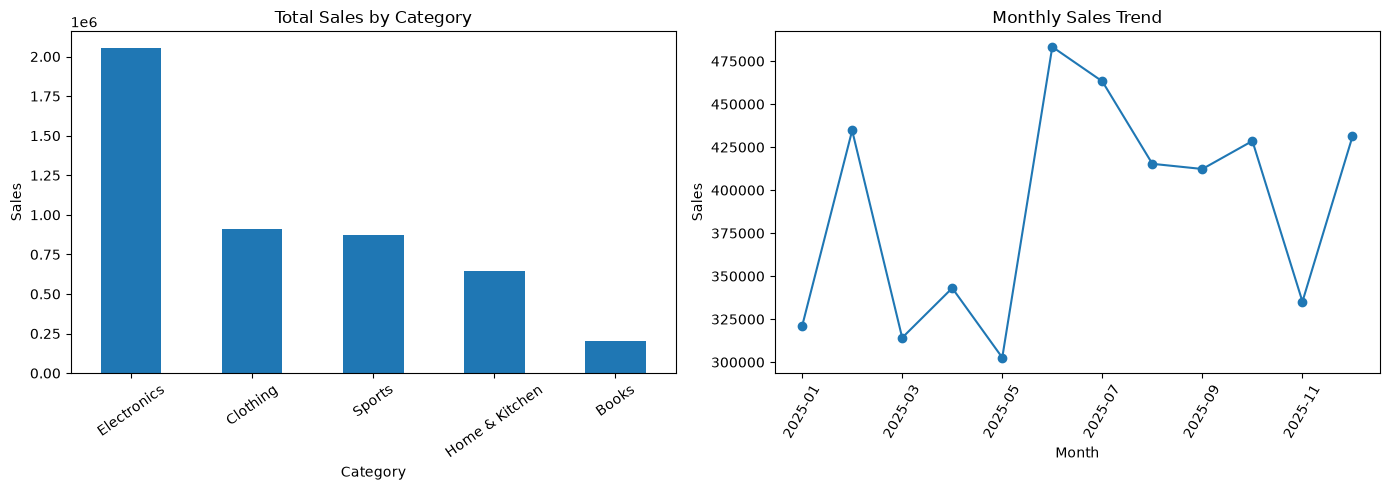

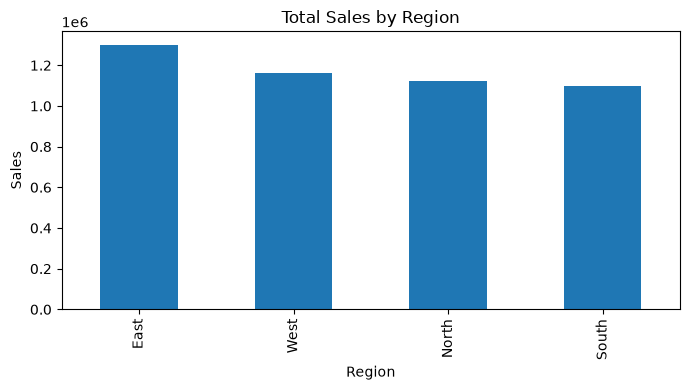

Top category: Electronics
Top region: East
Total revenue: 4684719.04


In [4]:
# 3. Exploratory data analysis (EDA)
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
monthly_sales = df.groupby("Month")["Sales"].sum()
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
category_sales.plot(kind="bar", ax=axes[0], title="Total Sales by Category")
axes[0].set_ylabel("Sales")
axes[0].tick_params(axis="x", rotation=35)
monthly_sales.plot(kind="line", marker="o", ax=axes[1], title="Monthly Sales Trend")
axes[1].set_ylabel("Sales")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

region_sales.plot(kind="bar", title="Total Sales by Region", figsize=(7,4), ylabel="Sales")
plt.tight_layout()
plt.show()

print("Top category:", category_sales.index[0])
print("Top region:", region_sales.index[0])
print("Total revenue:", round(df["Sales"].sum(), 2))


## Train and evaluate a prediction model


In [7]:
# 4. AI / Machine Learning: predict order sales
# Features are known at order time; Order_ID is excluded because it is only an identifier.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

features = ["Region", "Category", "Product", "Quantity", "Unit_Price", "Discount"]
X = df[features]
y = df["Sales"]

categorical_features = ["Region", "Category", "Product"]
numeric_features = ["Quantity", "Unit_Price", "Discount"]
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=150, random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² score: {r2:.3f}")
print("Note: metrics are for the synthetic demo dataset, not real business performance.")


MAE: 130.89
RMSE: 202.09
R² score: 0.996
Note: metrics are for the synthetic demo dataset, not real business performance.


## Visualize model predictions


,Actual_Sales,Predicted_Sales
0,889.25,920.324667
1,10202.98,10927.889333
2,2671.84,2721.446333
3,2496.85,2442.474267
4,1052.86,995.312600
5,572.82,586.482600
6,1347.30,1463.468533
7,2618.63,2841.004733
8,1719.22,1667.532333
9,1823.30,1684.247200


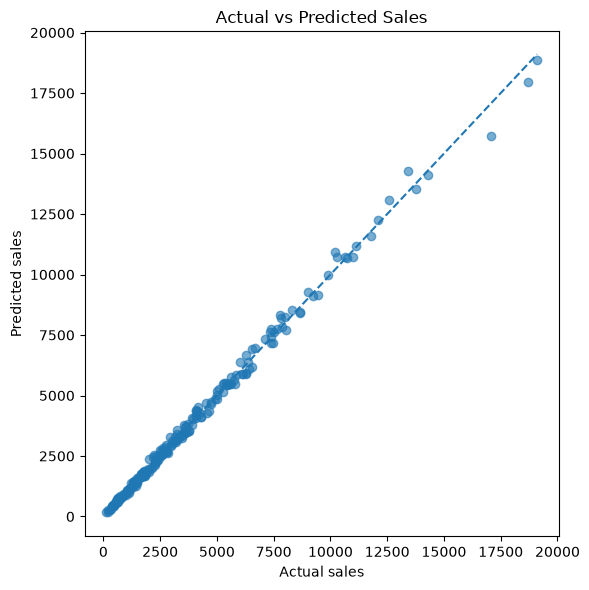

In [8]:
# 5. Compare actual and predicted sales
comparison = pd.DataFrame({"Actual_Sales": y_test.values, "Predicted_Sales": predictions})
display(comparison.head(10))

plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, alpha=0.6)
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
plt.plot(limits, limits, linestyle="--")
plt.xlabel("Actual sales")
plt.ylabel("Predicted sales")
plt.title("Actual vs Predicted Sales")
plt.tight_layout()
plt.show()


## Try a sample prediction


In [9]:
# 6. Example prediction for a new order
new_order = pd.DataFrame([{
    "Region": "North",
    "Category": "Electronics",
    "Product": "Headphones",
    "Quantity": 2,
    "Unit_Price": 1800.00,
    "Discount": 0.10
}])
estimated_sales = model.predict(new_order)[0]
print(f"Estimated sales for the example order: ₹{estimated_sales:,.2f}")


Estimated sales for the example order: ₹3,378.58
